# MediPredict AI — Exploratory Data Analysis & Leakage Audit

**Project:** Hospital appointment no-show prediction for reminder prioritisation
**Organisation:** ALGIONS AI LABS PRIVATE LIMITED

This notebook answers four questions before any modelling decision is made:

1. Is the data clean enough to trust, and what had to be removed?
2. Which booking-time factors relate to missed appointments?
3. Which columns would leak information the model will not have at booking time?
4. How well does the final model do, and is that close to what this data allows?

> **Data note.** `data/raw/appointments.csv` is synthetic (generated by `src/generate_data.py` in the Kaggle
> *Medical Appointment No Shows* schema). Findings describe that generator. The pipeline runs unchanged on the real file.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_DATA_FILE, MODEL_METADATA_FILE, FEATURE_POLICY, ALL_MODEL_FEATURES
from src.data_preprocessing import clean_appointment_data
from src.feature_engineering import split_chronologically

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
TEAL, RED, AMBER = "#0F766E", "#E11D48", "#D97706"

df_raw = pd.read_csv(RAW_DATA_FILE)
print(f"{len(df_raw):,} rows x {df_raw.shape[1]} columns")
df_raw.head()

110,527 rows x 14 columns


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,135449551,5600000,F,2016-05-28T14:11:16Z,2016-05-28T00:00:00Z,47,JESUS DE NAZARETH,0,0,0,0,0,0,No
1,624787849,5600001,M,2016-06-04T18:26:38Z,2016-07-27T00:00:00Z,45,ILHA DO PRÍNCIPE,0,0,0,0,0,1,No
2,628000571,5600002,F,2016-04-19T16:49:28Z,2016-05-09T00:00:00Z,39,MARIA ORTIZ,0,0,0,0,0,1,No
3,898721789,5600003,F,2016-04-11T12:23:52Z,2016-04-29T00:00:00Z,52,RESISTÊNCIA,0,0,0,0,0,0,No
4,953959916,5600004,M,2016-06-01T09:30:28Z,2016-06-01T00:00:00Z,10,MARIA ORTIZ,0,0,0,0,0,0,No


## 1. Data quality

In [2]:
print("Missing values per column:", int(df_raw.isna().sum().sum()))
print("Duplicate AppointmentID:", int(df_raw["AppointmentID"].duplicated().sum()))
print("Unique patients:", f"{df_raw['PatientId'].nunique():,}")

df, audit = clean_appointment_data(df_raw)
pd.Series(audit["dropped_reasons"], name="rows removed").to_frame()

Missing values per column: 0
Duplicate AppointmentID: 0
Unique patients: 51,571


,rows removed
duplicate_appointment_id,0
negative_waiting_days,1
invalid_age,2
null_records,0


In [3]:
print(f"Kept {audit['final_rows']:,} of {audit['initial_rows']:,} rows ({audit['retention_rate']}%).")
print(f"No-show rate after cleaning: {audit['no_show_rate']}%  ->  accuracy is a misleading metric here;"
      " a model that predicts 'attended' for everyone is already ~79% accurate.")

Kept 110,524 of 110,527 rows (100.0%).
No-show rate after cleaning: 20.74%  ->  accuracy is a misleading metric here; a model that predicts 'attended' for everyone is already ~79% accurate.


## 2. What relates to missed appointments?

Helper: no-show rate per group with a 95% Wilson interval, so small groups are not over-read.

In [4]:
def rate_ci(keys):
    g = df.groupby(keys, observed=True)["no_show"].agg(n="count", k="sum")
    p, n, z = g["k"] / g["n"], g["n"], 1.96
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return g.assign(rate=p * 100, lo=(centre - half) * 100, hi=(centre + half) * 100)

def bar(g, title, color=TEAL, ax=None):
    ax = ax or plt.gca()
    ax.bar(g.index.astype(str), g["rate"], color=color, yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], capsize=3)
    ax.axhline(df["no_show"].mean() * 100, ls=":", c=AMBER, label="overall")
    ax.set_title(title); ax.set_ylabel("No-show rate (%)"); ax.legend(loc="upper left")
    return ax

### 2.1 Lead time — the strongest signal

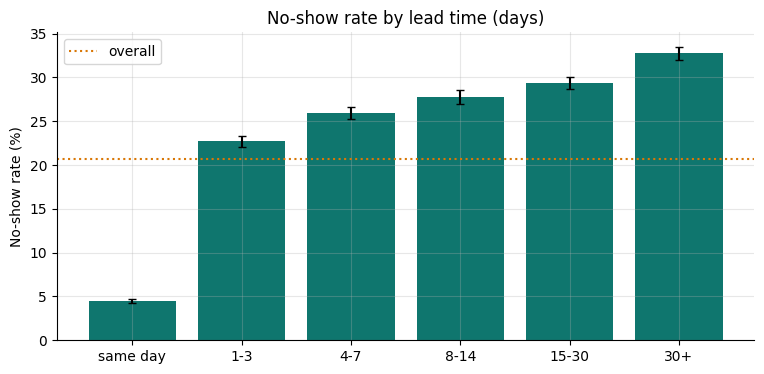

,n,rate,lo,hi
waiting_days,,,,
same day,32884,4.5,4.3,4.7
1-3,17068,22.7,22.1,23.4
4-7,15832,25.9,25.3,26.6
8-14,12422,27.7,26.9,28.5
15-30,16596,29.4,28.7,30.0
30+,15722,32.8,32.0,33.5


In [5]:
lead = rate_ci(pd.cut(df["waiting_days"], [-1, 0, 3, 7, 14, 30, 1000],
                      labels=["same day", "1-3", "4-7", "8-14", "15-30", "30+"]))
bar(lead, "No-show rate by lead time (days)"); plt.show()
lead[["n", "rate", "lo", "hi"]].round(1)

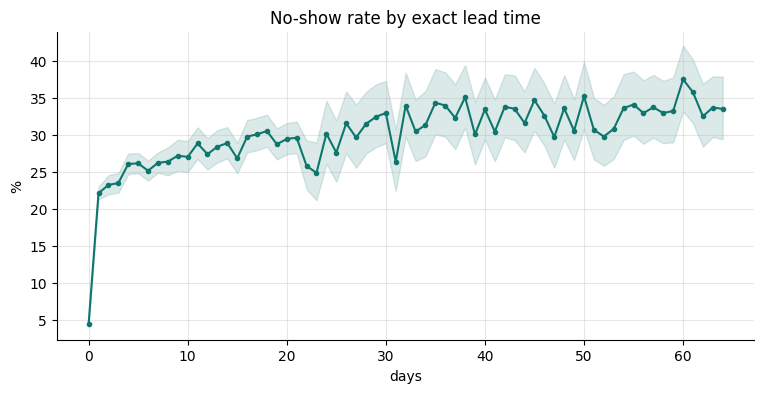

In [6]:
curve = rate_ci(df["waiting_days"].clip(upper=70))
curve = curve[curve["n"] >= 100]
plt.fill_between(curve.index, curve["lo"], curve["hi"], color=TEAL, alpha=.15)
plt.plot(curve.index, curve["rate"], c=TEAL, marker="o", ms=3)
plt.title("No-show rate by exact lead time"); plt.xlabel("days"); plt.ylabel("%"); plt.show()

Same-day bookings are almost always kept; after that the rate rises quickly and then flattens, roughly like
`log(1 + days)`. That shape is why the pipeline adds `log_waiting_days` and `is_same_day` features: they let a
simple linear model follow the curve.

### 2.2 Patient profile and timing

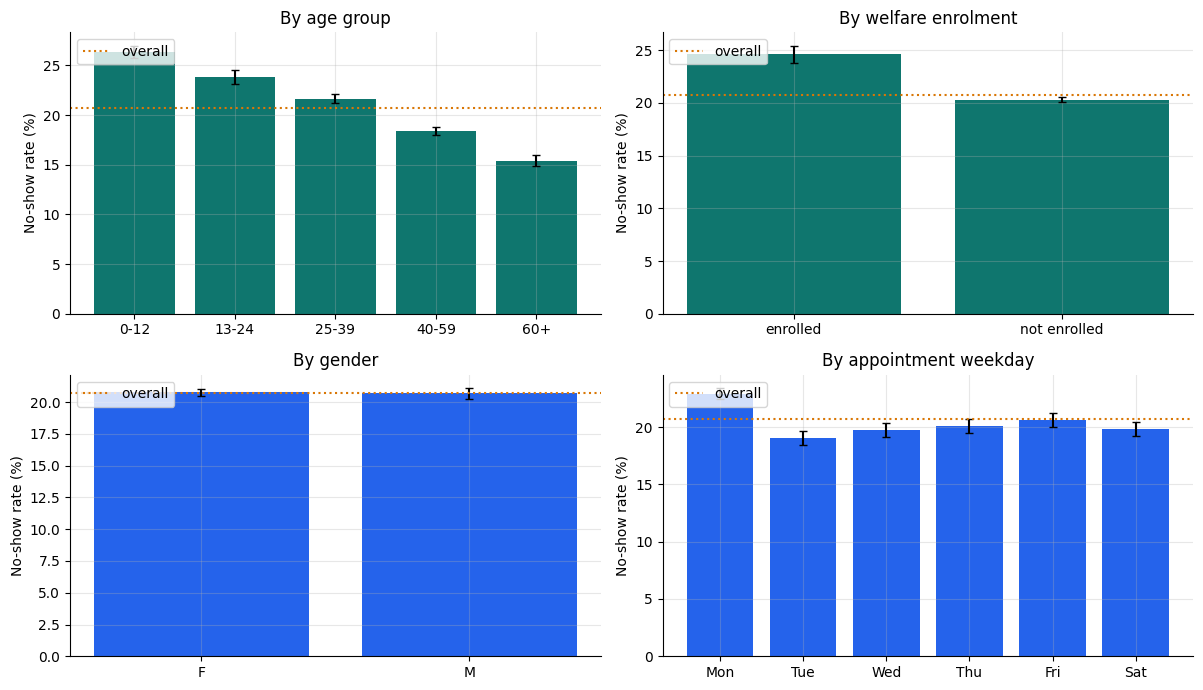

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
bar(rate_ci(pd.cut(df["Age"], [-1, 12, 24, 39, 59, 200], labels=["0-12", "13-24", "25-39", "40-59", "60+"])),
    "By age group", ax=axes[0, 0])
bar(rate_ci(df["Scholarship"].map({0: "not enrolled", 1: "enrolled"})), "By welfare enrolment", ax=axes[0, 1])
bar(rate_ci(df["Gender"]), "By gender", color="#2563EB", ax=axes[1, 0])
dow = pd.Categorical(df["AppointmentDay"].dt.day_name().str[:3],
                     ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"], ordered=True)
bar(rate_ci(pd.Series(dow, index=df.index)), "By appointment weekday", color="#2563EB", ax=axes[1, 1])
plt.tight_layout(); plt.show()

Younger patients and welfare-enrolled patients miss more often. Gender and weekday intervals overlap the
overall rate, so they are unlikely to help. The model still receives them, and the permutation-importance check
in section 5 confirms they contribute ~nothing, which is the honest outcome rather than a forced one.

## 3. Leakage audit

A feature is only usable if it is known **when the appointment is booked**. `SMS_received` fails that test:
reminders are sent *after* booking, and only for appointments far enough ahead.

In [8]:
sms = df.assign(lead=pd.cut(df["waiting_days"], [-1, 2, 7, 14, 30, 1000], labels=["0-2", "3-7", "8-14", "15-30", "30+"]))
print("Share of bookings that received an SMS, by lead time:")
print((sms.groupby("lead", observed=True)["SMS_received"].mean() * 100).round(1).to_string())
print()
print("No-show rate (%) by SMS, overall:")
print((df.groupby("SMS_received")["no_show"].mean() * 100).round(1).to_string())

Share of bookings that received an SMS, by lead time:
lead
0-2       0.0
3-7      54.5
8-14     54.9
15-30    55.5
30+      55.4

No-show rate (%) by SMS, overall:
SMS_received
0    17.0
1    28.7


In [9]:
(sms[sms["waiting_days"] >= 3].groupby(["lead", "SMS_received"], observed=True)["no_show"].mean() * 100).unstack().round(1)

SMS_received,0,1
lead,,
3-7,25.8,25.1
8-14,28.0,27.5
15-30,29.1,29.6
30+,32.5,32.9


Overall, SMS recipients appear to miss *more* often, but within the same lead-time band the SMS makes no
difference. The raw association is entirely driven by lead time, and the value itself is not known at booking.
Using it would leak post-booking information and teach a misleading pattern, so it is excluded.

The same governance check runs in code (`verify_feature_discipline`) and fails training if a prohibited column
ever reaches the feature matrix:

In [10]:
policy = pd.DataFrame(FEATURE_POLICY).T[["status", "category", "reason"]]
print("Model features:", ALL_MODEL_FEATURES)
policy

Model features: ['age', 'waiting_days', 'log_waiting_days', 'scheduled_hour', 'gender', 'neighbourhood_grouped', 'scheduled_day_of_week', 'appointment_day_of_week', 'scholarship', 'is_same_day']


,status,category,reason
PatientId,EXCLUDED,Identifier,Direct patient identifier. Prone to data leaka...
AppointmentID,EXCLUDED,Identifier,Internal primary key. Arbitrary sequential cou...
Hipertension,EXCLUDED,Clinical,Clinical diagnosis variable. Excluded per non-...
Diabetes,EXCLUDED,Clinical,Clinical diagnosis variable. Excluded per non-...
Alcoholism,EXCLUDED,Clinical,Sensitive clinical indicator. Excluded to prev...
Handcap,EXCLUDED,Clinical,Physical condition/disability indicator. Exclu...
SMS_received,EXCLUDED,Post-Booking Event,Post-booking event. Occurs after the schedulin...
Age,INCLUDED,Demographic,Available at booking. Cleaned to valid physiol...
Gender,INCLUDED,Demographic,Standard administrative demographic known at b...
Neighbourhood,INCLUDED,Geographic,Clinic / geographic catchment area. Top 25 ret...


## 4. Chronological split

In [11]:
X_tr, y_tr, X_va, y_va, X_te, y_te, split_meta, top_n = split_chronologically(df)
pd.DataFrame({k: v for k, v in split_meta.items() if isinstance(v, dict)}).T

,samples,no_show_rate,start_time,end_time
train,77366,20.7,2016-04-10 07:00:14+00:00,2016-05-22 09:29:51+00:00
validation,16578,20.96,2016-05-22 09:30:36+00:00,2016-05-31 10:00:51+00:00
test,16580,20.73,2016-05-31 10:01:06+00:00,2016-06-09 19:56:37+00:00


In [12]:
ends = [pd.Timestamp(split_meta[k]["end_time"]) for k in ("train", "validation")]
starts = [pd.Timestamp(split_meta[k]["start_time"]) for k in ("validation", "test")]
assert ends[0] <= starts[0] and ends[1] <= starts[1]
print("No temporal overlap: every validation booking is after every training booking, and likewise for test.")

No temporal overlap: every validation booking is after every training booking, and likewise for test.


## 5. Model results (from `models/model_metadata.json`)

In [13]:
meta = json.loads(Path(MODEL_METADATA_FILE).read_text(encoding="utf-8"))
cands = pd.DataFrame({k: v["metrics_at_optimal_threshold"] for k, v in meta["candidate_models_validation"].items()}).T
cands[["roc_auc", "pr_auc", "brier_score", "precision", "recall", "f1"]]

,roc_auc,pr_auc,brier_score,precision,recall,f1
Dummy (Baseline),0.5,0.2096,0.1656,0.2096,1.0,0.3465
Logistic Regression,0.6959,0.3381,0.2245,0.2913,0.8184,0.4297
Random Forest,0.694,0.3343,0.222,0.2839,0.8826,0.4297
HistGradientBoosting,0.6942,0.3387,0.2236,0.281,0.9004,0.4283


In [14]:
t = meta["test_evaluation"]["at_optimal_threshold"]
ceil = meta.get("reference_ceiling") or {}
print(f"Selected: {meta['model_name']}  |  threshold {meta['selected_operating_threshold']}")
print(f"Test ROC-AUC {t['roc_auc']:.4f}  (synthetic ceiling {ceil.get('roc_auc', float('nan')):.4f})")
print(f"Test PR-AUC  {t['pr_auc']:.4f}  (ceiling {ceil.get('pr_auc', float('nan')):.4f}; random = {split_meta['test']['no_show_rate'] / 100:.3f})")
print(f"Recall {t['recall']:.1%}  Precision {t['precision']:.1%}  Flagged {t['flagged_share']:.1%}  Brier {t['brier_score']:.4f}")

Selected: Logistic Regression (Calibrated)  |  threshold 0.18
Test ROC-AUC 0.7008  (synthetic ceiling 0.7012)
Test PR-AUC  0.3370  (ceiling 0.3392; random = 0.207)
Recall 90.0%  Precision 28.4%  Flagged 65.6%  Brier 0.1505


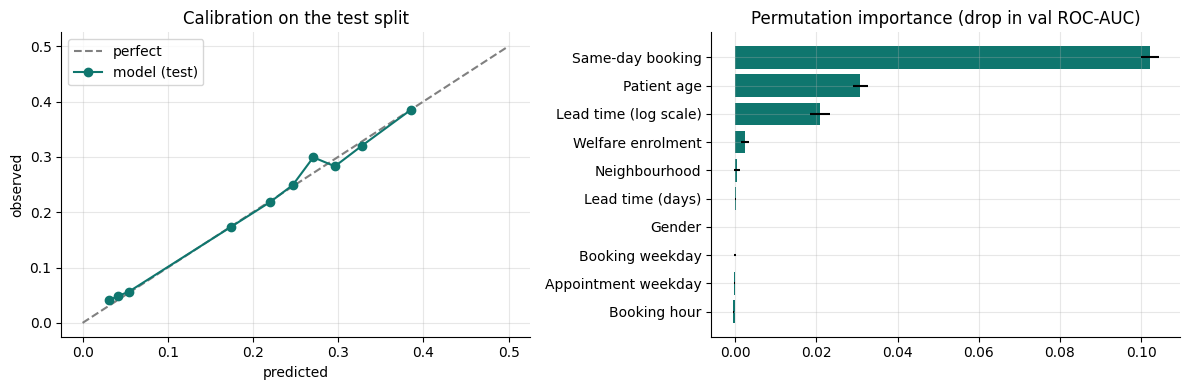

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cal = meta["calibration_curve"]
axes[0].plot([0, .5], [0, .5], ls="--", c="grey", label="perfect")
axes[0].plot(cal["prob_pred"], cal["prob_true"], marker="o", c=TEAL, label="model (test)")
axes[0].set_title("Calibration on the test split"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("observed"); axes[0].legend()
fi = pd.DataFrame(meta["top_features"]).sort_values("importance")
axes[1].barh(fi["label"], fi["importance"], xerr=fi["std"], color=TEAL)
axes[1].set_title("Permutation importance (drop in val ROC-AUC)")
plt.tight_layout(); plt.show()

In [16]:
pd.concat({g: pd.DataFrame(r).set_index("group") for g, r in meta["subgroup_audit"].items()})[
    ["n", "observed_rate", "mean_predicted", "flag_rate", "recall", "precision"]].round(3)

n  observed_rate  mean_predicted  \
                  group                                                
Gender            Female        10693          0.207           0.204   
                  Male           5887          0.208           0.205   
Age group         0-12           2711          0.255           0.259   
                  13-24          2126          0.248           0.239   
                  25-39          3957          0.221           0.210   
                  40-59          5490          0.178           0.184   
                  60+            2296          0.158           0.149   
Welfare enrolment Enrolled       1620          0.246           0.251   
                  Not enrolled  14960          0.203           0.200   

                                flag_rate  recall  precision  
                  group                                       
Gender            Female            0.654   0.897      0.284  
                  Male              0.660   0.907      0.285  
Age group         0-12              0.683   0.934      0.349  
                  13-24             0.701   0.922      0.326  
                  25-39             0.687   0.926      0.298  
                  40-59             0.675   0.911      0.241  
                  60+               0.487   0.716      0.233  
Welfare enrolment Enrolled          0.695   0.940      0.333  
                  Not enrolled      0.652   0.895      0.279

## 6. Conclusions

* **Clean data:** only a handful of impossible rows (negative age, appointment before booking) were removed.
* **Signal:** lead time dominates (same-day bookings are rarely missed), followed by age and welfare enrolment.
  Gender, weekday and booking hour add nothing measurable.
* **Leakage:** `SMS_received` looks predictive only because it proxies lead time and is recorded after booking, so it
  is excluded together with identifiers and clinical fields.
* **Model:** a calibrated logistic regression matches tree ensembles on validation, is simpler to explain, and
  reaches the synthetic-data ceiling on the untouched test split. Higher accuracy is not available in this data;
  the remaining error is the generator's random noise.
* **Operations:** the F1-optimal threshold flags about two-thirds of bookings. Teams with limited call capacity
  should work the *Higher* band first (top ~15% of risk, ~37% observed no-show rate).
* **Fairness:** calibration holds within gender, age and welfare groups. Recall is lower for patients aged 60+,
  because their base rate is lower; a group-specific review threshold is the safer remedy than adding features.